# BEE 4750 Mini-Project 2: Dispatching New York’s Grid Under a Carbon

**Names**: Anthony Santos & Violeta Egan

**IDs**:

> **Due Date**
>
> Friday, 11/20/26, 9:00pm

## Overview

In 2013, New York’s grid still burned coal, ran the Indian Point nuclear
plant, and had almost no solar. In this project you will model how that
grid met demand hour by hour, find the price of electricity each hour,
and ask what impact a carbon price would have made: first by changing
which plants run, and then by changing what gets built.

### Instructions

- Students in BEE 4750 may work in groups of 2; students in BEE 5750
  work individually.
- Submit a **report of no more than 4 pages**, not counting figures,
  tables, code, and references, as a PDF to Gradescope. Answer every
  numbered question in the report and label each answer with its number
  (for example, **4.1**), then tag those pages in Gradescope.
- Put your code in an appendix or submit the notebook alongside the
  report. The report should read on its own without it.
- Parts 1–4 use linear programming, shadow prices, JuMP, and
  multi-period dispatch (October 14–28 and the October 26 lab). Part 5
  uses capacity expansion (November 2).

### Load Environment

The following code loads the environment and makes sure all needed
packages are installed. This should be at the start of most Julia
scripts.

In [1]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `c:\Users\thean\Downloads\BEE 4750\mp02\mp02`


In [2]:
using JuMP
using HiGHS
using CSV
using DataFrames
using Statistics
using Plots
using Measures
using Printf

## The System

We treat New York as a single node (no transmission limits) and model
every hour of 2013.

**Demand** is NYISO’s hourly load for 2013, summed over its eleven
zones. It ranges from about 12 GW overnight to a 34 GW summer peak.

**The existing fleet** is New York’s summer 2013 generating capability,
grouped by type. Each plant type can generate up to its available
capacity in each hour. The thermal types (nuclear, coal, steam, combined
cycle, and combustion turbines) can also change their output by at most
their ramp fraction of capacity from one hour to the next. Hydro, wind,
and solar have no ramp limit.

| Type | Capacity (MW) | Variable cost (\$/MWh) | CO<sub>2</sub> (t/MWh) | Ramp (per hour) | Availability |
|:-----------|-----------:|-----------:|-----------:|-----------:|:-----------|
| Nuclear | 5,411 | 8 | 0 | 0.25 | 88% |
| Hydro | 4,276 | 0 | 0 | – | budget |
| Coal | 1,548 | 24 | 1.00 | 0.70 | 100% |
| Oil and gas steam | 9,576 | 45 | 0.58 | 0.70 | 100% |
| Combined cycle | 8,991 | 30 | 0.43 | 0.70 | 100% |
| Combustion turbine | 4,911 | 40 | 0.55 | 1 | 100% |
| Wind | 1,634 | 0 | 0 | – | profile |
| Solar | 31.5 | 0 | 0 | – | profile |

Table 1: New York’s 2013 generating fleet.

The fleet file has a ninth row, combined cycle with carbon capture, with
no capacity: New York had none in 2013. It generates nothing in Parts
1–4 and becomes an option in Part 5.

**Hydro** can be dispatched in any hour up to its capacity, but its
total generation over the year cannot exceed **24,572 GWh**, New York’s
hydro generation in 2012. Most of that capacity is the New York Power
Authority’s plants on the Niagara and St. Lawrence rivers. At Niagara, a
1950 treaty with Canada sets how much of the river’s flow must go over
the falls rather than through the turbines, which limits the water
available for power. Water used in one hour is not available in another.

**Wind and solar** follow hourly capacity-factor profiles, rescaled so
their annual averages match New York’s observed values: 23.4% for wind
and 16.5% for solar.

**Non-served energy** is allowed but penalized at \$10,000/MWh, so the
problem is always feasible. A good plan should have none.

> **Data and Simplifications**
>
> Capacities are from NYISO’s *2013 Load & Capacity Data* report (the
> “Gold Book”), Table III-3a, summer capability; wind and solar use
> nameplate capacity. Coal, combined cycle, and combustion turbine
> variable costs are roughly what these plants cost to run at 2012–13
> fuel prices, and their emissions are the values used in lecture; the
> others are course assumptions. The wind capacity factor is from the
> Gold Book’s 2012 energy for wind plants in service all year, and the
> solar capacity factor is the Long Island Solar Farm’s in NYISO’s 2024
> Gold Book. The ramp fractions are hourly limits: coal’s and combined
> cycle’s are the rates of the large units in the RTS-GMLC test system
> (about 4 MW per minute on a 350 MW unit), steam is assumed to match
> coal, combustion turbines can reach full output within an hour, and
> nuclear’s is a course assumption.
>
> The model leaves out imports (New York imported roughly 15% of its
> electricity), pumped storage (1,407 MW), about 400 MW of small biomass
> and waste plants, and transmission limits between zones.

For comparison, in 2012 New York generated 139,137 GWh in-state: 29.4%
nuclear, 17.7% hydro, 2.2% wind, and 48.1% fossil, of which coal was
3.1%.

The data, ready to use:

In [3]:
# Statewide hourly demand: the sum of NYISO's eleven load zones [MW]
load_data = DataFrame(CSV.File("data/2013_hourly_load_NY.csv"))
zones = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K"]
demand = zeros(nrow(load_data))
for zone in zones
    demand .+= load_data[:, zone]
end

# Hourly wind and solar capacity factors, rescaled to New York's annual averages
profiles = DataFrame(CSV.File("data/wind_solar_capacity_factors.csv"))
wind_cf = profiles.Wind .* (0.234 / mean(profiles.Wind))
solar_cf = profiles.Solar .* (0.165 / mean(profiles.Solar))

# The existing fleet, as in the table above. Wind and solar availability come
# from the hourly profiles, not the Availability column. RampFraction is missing
# for hydro, wind and solar, which have no ramp limit. The last row, combined
# cycle with carbon capture, has no capacity until Part 5.
fleet = DataFrame(CSV.File("data/nyca_2013_fleet.csv"))

hydro_budget = 24_572_000   # annual hydro energy [MWh]
nse_cost = 10_000           # penalty on non-served energy [$/MWh]

10000

## Problems (Total: 100 Points)

### Part 1: Formulate the Dispatch Problem (15 points)

#### Problem 1.1 (15 points)

Formulate a linear program that decides how much each plant type
generates in every hour of 2013 to meet demand at the lowest total
variable cost. Define your decision variables (with units), objective,
and constraints: meeting demand each hour, each plant’s hourly
availability, ramping limits for the thermal types, and the hydro energy
budget. Explain each constraint in a sentence.

$\bold{Decision Variables:}$  
$$x_1 \text{ = nuclear production (MW)}$$
$$x_2 \text{ = hydropower production (MW)}$$
$$x_3 \text{ = coal production (MW)}$$
$$x_4 \text{ = oil and gas steam production (MW)}$$
$$x_5 \text{ = combined cycle production (MW)}$$
$$x_6 \text{ =  combustion turbine production (MW)}$$
$$x_7 \text{ = wind production (MW)}$$
$$x_8 \text{ = solar production (MW)}$$
  
$$y = \text{ amount of non-served energy (MWh)}$$
  

$\bold{Objective:}$  
$$\min_{\mathbf{x}, \mathbf{y}} \sum_{i}^{8} (VariableCost_i x_i + NSECost y)$$
$$\text{min C} = $$
  
$\bold{Constraints:}$  
This ensures that the sum of the total energy production is at least the demand of NY. 
$$\sum_{i}^{8} x_i \geq demand$$
This ensures that the the production at each capacity does not exceed its capacity.
$$ x_i \leq Capacity_i \cdot Availability_i$$
This ensures that the sum of the hydropower production does not exceed its budget.  
$$x_2 \leq 24,572,000 (MWh)$$
This accounts for the wind and solar profiles.  
$$x_7 \leq Capacity_7 * 0.234$$
$$x_8 \leq Capacity_8 * 0.165$$
This accounts for the ramping limits up and down for the thermal types.  
$$ x_{i, t} - x_{i, t-1} \leq Capacity_i \cdot RampFraction_i \text{  (ramp up)}$$
$$x_{i, t-1} - x_{i, t} \leq Capacity_i \cdot RampFraction_i \text{  (ramp down)}$$





### Part 2: Dispatching New York in 2013 (20 points)

#### Problem 2.1 (10 points)

Solve your model in JuMP with no carbon tax. Report the total variable
cost, annual CO<sub>2</sub> emissions, each plant type’s share of
generation, and any non-served energy. Compare your generation shares
with New York’s actual 2012 shares above, and give two reasons for the
largest differences.

In [4]:
no_carbontax = Model(HiGHS.Optimizer)
n = 8
hours = 1:8760

#decision variables
@variable(no_carbontax, x[1:n, t in hours] >= 0)  #production of each plant (MW)
@variable(no_carbontax, nse[t in hours] >= 0)  #non-served energy (MWh)

#objective
@objective(no_carbontax, Min, sum(fleet.VarCost[i] * x[i, t] for i in 1:n, t in hours) + nse_cost * sum(nse[t] for t in hours))

#constraints
@constraint(no_carbontax, [t in hours], sum(x[i, t] for i in 1:n) + nse[t] == demand[t])  #demand constraint
@constraint(no_carbontax, hydro_const, sum(x[2, t] for t in hours) <= hydro_budget)  #hydro energy budget
@constraint(no_carbontax, [i in 1:n, t in hours], x[i, t] <= fleet.Capacity[i] * fleet.Availability[i])  #capacity constraint
@constraint(no_carbontax, [t in hours], x[7, t] <= fleet.Capacity[7] * wind_cf[t])  #wind capacity constraint
@constraint(no_carbontax, [t in hours], x[8, t] <= fleet.Capacity[8] * solar_cf[t])  #solar capacity constraint
thermal = [i for i in 1:n if !ismissing(fleet.RampFraction[i])]
@constraint(no_carbontax, [i in thermal, t in 2:8760], x[i, t] - x[i, t-1] <= fleet.Capacity[i] * fleet.RampFraction[i])  #ramp up constraint
@constraint(no_carbontax, [i in thermal, t in 2:8760], x[i, t-1] - x[i, t] <= fleet.Capacity[i] * fleet.RampFraction[i])  #ramp down constraint

#solving
set_silent(no_carbontax)
optimize!(no_carbontax)

X = value.(x)
NSE = value.(nse)

production = [sum(X[i, :]) for i in 1:n]
var_cost = [sum(fleet.VarCost[i] * production[i]) for i in 1:n]
total_prod = sum(production)
annual_emissions = sum(production[i] * fleet.Emissions[i] for i in 1:n)
total_nse = sum(NSE)
nse_hours = count(>(1e-6), NSE)

shares = DataFrame(
    Type      = fleet.Type[1:n],
    MWh       = round.(production, digits=1),
    Share_pct = round.(100 .* production ./ total_prod, digits=2),
)
fossil = [3,4,5,6] # indices of fossil generators
@printf("Shares of total generation by type:\n")
for i in 1:n
    @printf("  %s: %.2f%%\n", shares.Type[i], shares.Share_pct[i])
end
@printf("Share of fossil generation: %.2f%%\n", round(100 * sum(production[fossil]) / total_prod, digits=2))
@printf("Total variable cost: \$%.3e\n", sum(var_cost))
@printf("Annual CO2 emissions (tons): %.3e\n", annual_emissions)
@printf("Non-served energy: %.3f MWh \n", total_nse)
@printf("Total generation: %.3f MWh \n", total_prod)


Shares of total generation by type:
  Nuclear: 25.51%
  Hydro: 15.03%
  Coal: 8.29%
  Steam: 0.77%
  CombinedCycle: 44.54%
  CombustionTurbine: 3.78%
  Wind: 2.05%
  Solar: 0.03%
Share of fossil generation: 57.39%
Total variable cost: $3.148e+09
Annual CO2 emissions (tons): 4.901e+07
Non-served energy: 0.000 MWh 
Total generation: 163513889.250 MWh 


More fossil fuel is burned than NY, a lot of that difference is attributed to coal. This can be due to a few things. One being that New York imported 15% of its electricity. For this model all of it has to be generated with no imports. Furthermore, this model makes coal much cheaper which was not the case in NY. 

#### Problem 2.2 (10 points)

Plot hourly generation by plant type, stacked, for one week in July.
Explain how the model uses hydro, given its annual budget.  
  


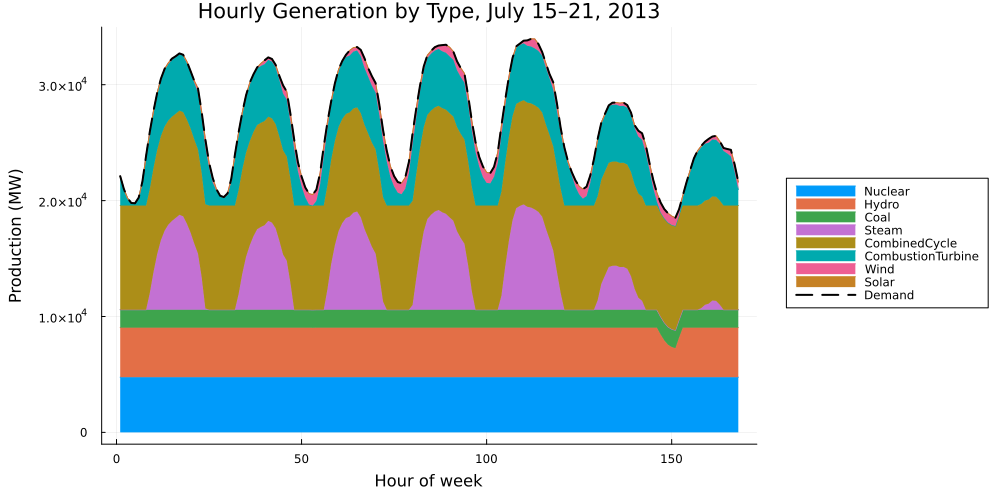

In [5]:
start_hr = (181 + 14) * 24 + 1
week = start_hr:(start_hr + 7*24 - 1)

gen_week = Matrix(X[:, week])' # rows = hours, columns = plant types
labels = permutedims(fleet.Type[1:n]) # row vector of names for the legend

p = areaplot(1:length(week), gen_week,
    label = labels,
    title = "Hourly Generation by Type, July 15–21, 2013",
    xlabel = "Hour of week",
    ylabel = "Production (MW)",
    legend = :outerright,
    size = (1000, 500),
    left_margin = 5mm, bottom_margin = 5mm)

plot!(p, 1:length(week), demand[week],
    label = "Demand", color = :black, linewidth = 2, linestyle = :dash)

display(p)

Hydro is at its full 4,276 MW in nearly every hour. It only drops, to about 2,500 MW, in the low-demand hours around hour 150. Hydro costs nothing to run, but it cannot run all year due to its capacity factor not being 1. Its hours are spent when the marginal unit of energy is cheaper than it.  

### Part 3: The Value of Water (10 points)

#### Problem 3.1 (10 points)

Report the shadow price of the hydro budget and interpret it. Suppose
enough extra water could be diverted through the Niagara turbines to
generate one more MWh over the year: what would that MWh be worth, and
why that value? Be careful with the sign.

In [6]:
hydro_sp = shadow_price(hydro_const)
@printf("Shadow price of hydro energy budget: \$%.2f/MWh\n", hydro_sp)

Shadow price of hydro energy budget: $-30.00/MWh


It's negative because relaxing saves 30 bucks. Adding an extra MWh of water means a positive $30 gain in savings because at the most expensive hours hydro is at full capcacity. The extra water would run in an hour where combined cycle is the marginal unit, so it saves combined cycle's $30/MWh fuel cost.

### Part 4: A Carbon Tax (25 points)

#### Problem 4.1 (15 points)

Add a carbon tax of $\tau$ dollars per tonne of CO<sub>2</sub> to your
model, and show how it enters your objective. Solve the dispatch problem
with taxes of \$0, \$20, \$40, \$60, and \$100 per tonne, and report
annual emissions and each fossil plant type’s share of generation at
each tax in a table. Between which taxes do emissions drop, and which
plant type moves ahead of coal in each? Why does coal keep running after
it falls behind combined cycle plants?

A carbon tax of $\tau$ \$/t adds $\tau e_i$ to each plant's cost per MWh, where $e_i$ is its CO₂ rate (t/MWh):

$$\min_{x,y} \sum_{i=1}^{8}\sum_{t=1}^{8760} (c_i + \tau e_i)\,x_{i,t} + 10{,}000\sum_{t=1}^{8760} y_t$$

The constraints are unchanged. The tax only reorders the merit order by changing each plant's effective cost $c_i + \tau e_i$.

In [7]:
function solve_dispatch(τ)
    m = Model(HiGHS.Optimizer); set_silent(m)
    n, T = 8, 8760
    @variable(m, x[1:n, 1:T] >= 0)
    @variable(m, nse[1:T] >= 0)
    eff = fleet.VarCost[1:n] .+ τ .* fleet.Emissions[1:n]   # carbon tax enters here
    @objective(m, Min, sum(eff[i] * x[i, t] for i in 1:n, t in 1:T) + nse_cost * sum(nse))
    @constraint(m, [t in 1:T], sum(x[:, t]) + nse[t] == demand[t])
    @constraint(m, sum(x[2, :]) <= hydro_budget)
    @constraint(m, [i in 1:n, t in 1:T], x[i, t] <= fleet.Capacity[i] * fleet.Availability[i])
    @constraint(m, [t in 1:T], x[7, t] <= fleet.Capacity[7] * wind_cf[t])
    @constraint(m, [t in 1:T], x[8, t] <= fleet.Capacity[8] * solar_cf[t])
    thermal = [i for i in 1:n if !ismissing(fleet.RampFraction[i])]
    @constraint(m, [i in thermal, t in 2:T], x[i, t] - x[i, t-1] <= fleet.Capacity[i] * fleet.RampFraction[i])
    @constraint(m, [i in thermal, t in 2:T], x[i, t-1] - x[i, t] <= fleet.Capacity[i] * fleet.RampFraction[i])
    optimize!(m)
    return vec(sum(value.(x), dims=2))   # annual MWh by type
end

taxes = [0, 20, 40, 60, 100]
results = DataFrame(Tax=Int[], Emissions_Mt=Float64[], Coal=Float64[],
                    Steam=Float64[], CC=Float64[], CT=Float64[])
for τ in taxes
    p = solve_dispatch(τ)
    sh = round.(100 .* p ./ sum(p), digits=2)
    push!(results, (τ, round(sum(p .* fleet.Emissions[1:8]) / 1e6, digits=2),
                    sh[3], sh[4], sh[5], sh[6]))
end
results

Row,Tax,Emissions_Mt,Coal,Steam,CC,CT
,Int64,Float64,Float64,Float64,Float64,Float64
1,0,49.01,8.29,0.77,44.54,3.78
2,20,46.08,5.15,0.77,47.69,3.78
3,40,42.72,0.58,0.77,47.69,8.34
4,60,42.32,0.01,1.35,47.69,8.35
5,100,42.32,0.01,1.35,47.69,8.35


Emissions drop between $0–20 (combined cycle moves ahead of coal), $20–40 (combustion turbines move ahead), and $40–60 (steam moves ahead), falling from 49.01 to 42.32 Mt. Between $60 and $100 they change little, since coal is already last among the fossil types.

Coal keeps running after combined cycle passes it because there isn't enough combined cycle capacity. After nuclear, hydro, and wind, the remaining load is larger than combined cycle's capacity in most hours, so the next-cheapest unit still runs. That's coal. Even at $100/t, peak hours need every fossil plant because everything else can't meet the total demand.

#### Problem 4.2 (10 points)

Is there any tax that brings emissions below 40 million tonnes per year
by changing only which existing plants run? Identify the lowest
emissions redispatch can reach, and explain what sets that floor.

In [8]:
for τ in [100, 200, 500, 1000]
    p = solve_dispatch(τ)
    @printf("τ = %4d \$/t: %.2f Mt\n", τ, sum(p .* fleet.Emissions[1:8]) / 1e6)
end

τ =  100 $/t: 42.32 Mt
τ =  200 $/t: 42.32 Mt
τ =  500 $/t: 42.32 Mt
τ = 1000 $/t: 42.32 Mt


No. Raising the tax to \$200 or \$1,000/t gives the same 42.32 Mt as \$60/t, so the lowest emissions redispatch can reach is about 42.3 Mt, above the 40 Mt target.

The floor is set by the carbon tax which only changes which existing plants run and it can't add new ones. $60/t already had the cleanest order of dispatch. Nuclear, hydro, wind, and solar are maxed out. The rest is filled by fossils.

### Part 5: Building New Capacity (30 points)

The state can now build six kinds of new capacity: combined cycle,
combustion turbines, wind, solar, hydro, and combined cycle with carbon
capture. New capacity behaves like the existing plants of the same type:
the same variable cost, emissions, and availability, and for the gas
plants the same ramp fraction. Two of the six need more detail:

- **Hydro.** The only sites are existing dams that have no turbines, so
  at most 295 MW can be built. We assume each MW of new hydro generates,
  on average, as much as each MW of existing hydro: each new MW raises
  the annual hydro generating capacity by 24,572,000 MWh ÷ 4,276 MW ≈
  5,746 MWh.
- **Combined cycle with carbon capture.** This is the fleet file’s last
  row. It captures 90% of its CO<sub>2</sub>, so it emits 0.05 t/MWh. It
  costs \$39/MWh to run, more than a combined cycle plant, because it
  burns more gas and pays to move and store the CO<sub>2</sub> it
  captures.

Annualized costs of new capacity are in `data/new_capacity_costs.csv`
(in \$ per MW of capacity per year): `Cost2013` is from 2013 cost
estimates and `CostToday` from 2025 ones.

In [9]:
new_costs = DataFrame(CSV.File("data/new_capacity_costs.csv"))
hydro_build_limit = 295   # most new hydro that can be built [MW]

295

> **New Capacity: Data and Cautions**
>
> The annualized costs are capital costs from the U.S. Energy
> Information Administration’s 2013 and 2025 reports on new generating
> plants, spread over 30 years at 7%, plus fixed operating costs. The
> 295 MW of hydro is Oak Ridge National Laboratory’s 2012 estimate of
> the capacity that New York’s dams without turbines could support.
> Capture’s variable cost of \$39/MWh includes about \$4.50/MWh to move
> and store the 0.45 t of CO<sub>2</sub> it captures from each MWh, at
> \$10 per tonne.
>
> Keep two things in mind when you interpret your results. First, the
> 2013 cost of capture is an estimate for a kind of plant that had not
> been built at commercial scale. Second, the two reports describe
> different hydro plants, 500 MW in 2013 and 100 MW in 2025, so part of
> the increase in hydro’s cost between them comes from comparing a
> larger plant with a smaller one, not from a change in what the same
> plant costs.

#### Problem 5.1 (8 points)

Extend your model to include build decisions, using 2013 costs. Explain
what changes in the objective and the constraints. With no emissions
policy, what does the model build, and why? Compare the cost of a MWh
from new wind with the cost of the fuel it would replace.

In [10]:
function solve_expansion(; costcol=:Cost2013, τ=0.0, emis_cap=nothing)
    m = Model(HiGHS.Optimizer); set_silent(m)
    n, T = 9, 8760
    capcost = Dict(r.Type => r[costcol] for r in eachrow(new_costs))

    @variable(m, x[1:n, 1:T] >= 0) # generation (MW)
    @variable(m, nse[1:T] >= 0)
    @variable(m, newcap[1:n] >= 0) # new capacity (MW)
    for i in 1:n  # nuclear, coal, steam can't be built
        haskey(capcost, fleet.Type[i]) || fix(newcap[i], 0; force=true)
    end
    @constraint(m, newcap[2] <= hydro_build_limit)

    cap = fleet.Capacity .+ newcap  # existing + new
    avail(i, t) = i == 7 ? wind_cf[t] : i == 8 ? solar_cf[t] : fleet.Availability[i]

    @constraint(m, [t in 1:T], sum(x[:, t]) + nse[t] == demand[t])
    @constraint(m, [i in 1:n, t in 1:T], x[i, t] <= avail(i, t) * cap[i])
    @constraint(m, sum(x[2, :]) <= hydro_budget + (hydro_budget / fleet.Capacity[2]) * newcap[2])
    thermal = [i for i in 1:n if !ismissing(fleet.RampFraction[i])]
    @constraint(m, [i in thermal, t in 2:T], x[i, t] - x[i, t-1] <= fleet.RampFraction[i] * cap[i])
    @constraint(m, [i in thermal, t in 2:T], x[i, t-1] - x[i, t] <= fleet.RampFraction[i] * cap[i])

    @expression(m, emis, sum(fleet.Emissions[i] * x[i, t] for i in 1:n, t in 1:T))
    emis_cap === nothing || @constraint(m, capcon, emis <= emis_cap)

    @objective(m, Min,
        sum((fleet.VarCost[i] + τ * fleet.Emissions[i]) * x[i, t] for i in 1:n, t in 1:T) +
        nse_cost * sum(nse) +
        sum(get(capcost, fleet.Type[i], 0) * newcap[i] for i in 1:n))
    optimize!(m)
    return m
end

m51 = solve_expansion()
DataFrame(Type = fleet.Type, NewMW = round.(value.(m51[:newcap]), digits=1))

Row,Type,NewMW
,DataStri…,Float64
1,Nuclear,0.0
2,Hydro,0.0
3,Coal,0.0
4,Steam,0.0
5,CombinedCycle,0.0
6,CombustionTurbine,0.0
7,Wind,0.0
8,Solar,0.0
9,CombinedCycleCapture,0.0


With no policy nothing is built which is why 0 MW is built in total. This is due to each option costing more than it would save. The existing plants can already meet demand every hour, so building something new only makes sense if its fuel savings pay for it, and nothing does.

Wind is the clearest example. One MW of wind makes about 8,760 × 0.234 ≈ 2,050 MWh a year. At \$217,888 per MW-year, that works out to about \$106 per MWh. Wind has no fuel cost, but the power it would replace is mostly combined cycle at \$30/MWh. Paying \$106 to save \$30 doesn't make sense, so the model skips it.

#### Problem 5.2 (10 points)

Cap annual emissions at 40 million tonnes, still with 2013 costs. What
does the model build, what does the system cost, and what is the shadow
price of the cap? Explain what the new plants replace.

In [11]:
m52 = solve_expansion(emis_cap=40e6)
p = vec(sum(value.(m52[:x]), dims=2))
DataFrame(Type = fleet.Type,
          NewMW = round.(value.(m52[:newcap]), digits=1),
          Share = round.(100 .* p ./ sum(p), digits=2))

Row,Type,NewMW,Share
,DataStri…,Float64,Float64
1,Nuclear,0.0,25.51
2,Hydro,295.0,16.06
3,Coal,0.0,0.0
4,Steam,0.0,0.98
5,CombinedCycle,369.3,49.28
6,CombustionTurbine,0.0,4.8
7,Wind,0.0,2.05
8,Solar,0.0,0.03
9,CombinedCycleCapture,240.8,1.29


In [12]:
@printf("Total cost: \$%.3fB\n", objective_value(m52) / 1e9)
@printf("Emissions: %.2f Mt\n", value(m52[:emis]) / 1e6)
@printf("Shadow price of cap: \$%.2f/t\n", shadow_price(m52[:capcon]))

Total cost: $3.374B
Emissions: 40.00 Mt
Shadow price of cap: $-57.80/t


With a 40 Mt cap and 2013 costs, the model builds 295 MW of new hydro (the maximum), 369 MW of new combined cycle, and 241 MW of combined cycle with capture, and no wind, solar, or combustion turbines. The system costs $3.37B a year, about $226M more than the $3.15B with no cap. The shadow price of the cap is −$57.80/t, meaning loosening the cap by one tonne would save $57.80, so it works like a $57.80/t carbon price. The new plants replace coal, which drops from 8.3% of generation to about zero, because at that carbon price coal effectively costs about $82/MWh. Counting build costs, new hydro comes to about $44/MWh and both new gas options to about $65/MWh, so all three beat coal while wind ($106/MWh) still doesn't.

#### Problem 5.3 (12 points)

Repeat 5.2’s capped problem with today’s costs. What gets built now, and
what is the shadow price of the same cap? Then remove the cap and
instead impose a carbon tax equal to that shadow price. Compare the two
solutions, and explain the result using what you know about shadow
prices. What does the change from 5.2 tell you about the role of a
carbon price when technology costs fall?

> **Working With JuMP Output**
>
> `value.(x)` returns a JuMP container; use `value.(x).data` or index it
> with `value(x[g, t])` to get plain numbers for plotting. End cells
> that build large sets of variables or constraints with a semicolon to
> suppress long printed output. For a constraint `c`, `shadow_price(c)`
> reports how the objective changes as the constraint is relaxed; check
> its sign against your intuition. `fleet.RampFraction` is `missing` for
> the types with no ramp limit; test for that with `ismissing`.

In [1]:
function solve_expansion(; costcol=:Cost2013, τ=0.0, emis_cap=nothing)
    m = direct_model(HiGHS.Optimizer())              # faster model build
    set_silent(m)
    set_attribute(m, "solver", "ipm")                # interior point: faster on big LPs
    n, T = 9, 8760
    capcost = Dict(r.Type => r[costcol] for r in eachrow(new_costs))

    @variable(m, x[1:n, 1:T] >= 0)
    @variable(m, nse[1:T] >= 0)
    @variable(m, newcap[1:n] >= 0)
    for i in 1:n
        haskey(capcost, fleet.Type[i]) || fix(newcap[i], 0; force=true)
    end
    @constraint(m, newcap[2] <= hydro_build_limit)

    cap = fleet.Capacity .+ newcap
    avail(i, t) = i == 7 ? wind_cf[t] : i == 8 ? solar_cf[t] : fleet.Availability[i]

    @constraint(m, [t in 1:T], sum(x[i, t] for i in 1:n) + nse[t] == demand[t])
    @constraint(m, [i in 1:n, t in 1:T], x[i, t] <= avail(i, t) * cap[i])
    @constraint(m, sum(x[2, t] for t in 1:T) <= hydro_budget + (hydro_budget / fleet.Capacity[2]) * newcap[2])
    thermal = [i for i in 1:n if !ismissing(fleet.RampFraction[i])]
    @constraint(m, [i in thermal, t in 2:T], x[i, t] - x[i, t-1] <= fleet.RampFraction[i] * cap[i])
    @constraint(m, [i in thermal, t in 2:T], x[i, t-1] - x[i, t] <= fleet.RampFraction[i] * cap[i])

    @expression(m, emis, sum(fleet.Emissions[i] * x[i, t] for i in 1:n, t in 1:T))
    emis_cap === nothing || @constraint(m, capcon, emis <= emis_cap)

    @objective(m, Min,
        sum((fleet.VarCost[i] + τ * fleet.Emissions[i]) * x[i, t] for i in 1:n, t in 1:T) +
        nse_cost * sum(nse) +
        sum(get(capcost, fleet.Type[i], 0) * newcap[i] for i in 1:n))
    optimize!(m)
    return m
end

m53 = solve_expansion(costcol=:CostToday, emis_cap=40e6);
λ = shadow_price(m53[:capcon])

τ = -λ
m53tax = solve_expansion(costcol=:CostToday, τ=τ);

cost_cap = objective_value(m53) / 1e9
cost_tax = (objective_value(m53tax) - τ * value(m53tax[:emis])) / 1e9   # leave out tax payments

@printf("Shadow price of cap: \$%.2f/t\n", λ)
@printf("Cap: %.2f Mt, \$%.3fB\n", value(m53[:emis]) / 1e6, cost_cap)
@printf("Tax: %.2f Mt, \$%.3fB\n", value(m53tax[:emis]) / 1e6, cost_tax)

DataFrame(Type = fleet.Type,
          Cap_NewMW = round.(value.(m53[:newcap]), digits=1),
          Tax_NewMW = round.(value.(m53tax[:newcap]), digits=1))

LoadError: LoadError: UndefVarError: `@variable` not defined in `Main`
Suggestion: check for spelling errors or missing imports.
in expression starting at c:\Users\thean\Downloads\BEE 4750\mp02\mp02\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y112sZmlsZQ==.jl:8

In [ ]:
@printf("Cap: %.2f Mt, \$%.3fB\n", value(m53[:emis]) / 1e6, cost_cap)
@printf("Tax: %.2f Mt, \$%.3fB\n", value(m53tax[:emis]) / 1e6, cost_tax)

With today's costs and the 40 Mt cap, the model builds only wind (about 2,740 MW) and solar (about 1,645 MW), and the cap's shadow price drops to −\$26.69/t. Replacing the cap with a \$26.69/t tax gives the same result: the same builds within a few MW, 40.00 Mt of emissions, and \$3.31B in system cost (not counting tax payments). That's what a shadow price means: it's the cost of cutting the last tonne under the cap, so a tax at that price pushes the model to cut emissions until the next tonne would cost more than the tax, which is exactly where the cap stopped it. Compared with 5.2, cheaper wind and solar mean the same 40 Mt target now needs less than half the carbon price (\$26.69 vs. \$57.80) and costs less overall. Cheap technology isn't enough by itself, though: with today's costs and no policy the model still builds nothing and emits 49 Mt, so a carbon price is still needed, it just doesn't have to be as high.

## References

List any external references consulted, including classmates.